# Load data

In [1]:
import rpy2.robjects as robjects
from rpy2.robjects import numpy2ri
import numpy as np
import pickle

# --- Setup rpy2 ---
# This line is crucial to allow conversion between R and NumPy objects
numpy2ri.activate()

# Define file paths
rdata_path = 'FRED-MD data/fredmd_data.RData'
output_path = 'FRED-MD data/fredmd_data.pkl'

print(f"Attempting to load '{rdata_path}' using rpy2...")

try:
    # --- Use R to load the data, supplied from Cho ---
    # This command is sent to the R process to execute: load("fredmd_data.RData")
    robjects.r(f"load('{rdata_path}')")

    # --- Access the loaded R object ---
    # After loading, the 'fredmd_data' object exists in R's global environment.
    # We can access it by name.
    r_object = robjects.r['fredmd_data']

    print("Successfully accessed the 'fredmd_data' object from R.")

    # --- Convert the R object to a Python dictionary of NumPy arrays ---
    # We access each component of the R list using .rx2('component_name')
    # and convert it to a NumPy array.
    python_data = {
        'X': np.array(r_object.rx2('X')),
        'y': np.array(r_object.rx2('y')).flatten(), # .flatten() to ensure 1D
        'date': np.array(r_object.rx2('date')).flatten()
    }
    
    print("\nData converted to Python format successfully.")
    print("Shape of X:", python_data['X'].shape)
    print("Shape of y:", python_data['y'].shape)
    print("Number of dates:", len(python_data['date']))

    # --- Save to a Python-native format ---
    # This is highly recommended so you don't have to do this conversion again.
    with open(output_path, 'wb') as f:
        pickle.dump(python_data, f)
    

except Exception as e:
    print(f"\nAn error occurred: {e}")
    print("Please ensure that R is installed and that the rpy2 Python package is installed correctly.")

Attempting to load 'FRED-MD data/fredmd_data.RData' using rpy2...
Successfully accessed the 'fredmd_data' object from R.

Data converted to Python format successfully.
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773


In [1]:
import pickle
import numpy as np

# Define the path to your .pkl file
pkl_path = '/scratch/ga442/Weighted-ERM/FRED-MD data/fredmd_data.pkl'
pkl_path_local = 'FRED-MD data/fredmd_data.pkl'

# Open the file in binary read mode ('rb')
try:
    with open(pkl_path, 'rb') as f:
        # Load the data from the file
        loaded_data = pickle.load(f)
except FileNotFoundError:
    with open(pkl_path_local, 'rb') as f:
        # Load the data from the file
        loaded_data = pickle.load(f)


# Assign the data to your variables
X = loaded_data['X']
y = loaded_data['y']
date = loaded_data['date']
X_ = X.copy()
y_ = y.copy()
date_ = date.copy()

# --- Verification (Optional but good practice) ---
print("Data loaded successfully!")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")
print(f"Number of dates: {len(date)}")
print(f"First 5 dates: {date[:5]}")# Load the python

Data loaded successfully!
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773
First 5 dates: ['1960-01' '1960-02' '1960-03' '1960-04' '1960-05']


# Approximate chgpt search

In [ ]:
import numpy as np
import jax.numpy as jnp
import jax
from functools import partial
from tqdm import tqdm
import scipy.special
import math

# --- Helper Functions from Original Code ---
def _unrank_combination(rank, k, n):
    """
    Generates the k-combination of {0, ..., n-1} with the given lexicographical rank.
    This is a standard, correct implementation using the combinadic method.
    It produces the combination in descending order.
    """
    if k < 0 or k > n:
        raise ValueError("Invalid combination parameters k, n")
    if rank < 0 or rank >= scipy.special.comb(n, k, exact=True):
        raise ValueError("Rank is out of bounds.")
        
    result = np.zeros(k, dtype=np.int64)
    current_rank = rank
    
    # Start with the largest possible element, n-1
    j = n - 1
    
    # Iterate from the largest element of the combination down to the smallest
    for i in range(k, 0, -1):
        # Find the largest element v (where v < j) for the current position
        v = j
        while scipy.special.comb(v, i, exact=True) > current_rank:
            v -= 1
        
        result[k - i] = v  # Store the element
        current_rank -= scipy.special.comb(v, i, exact=True)
        j = v - 1
            
    return np.sort(result) # Return in ascending order for consistency

@partial(jax.jit, static_argnames=['M', 'γ', 'n'])
def _calculate_gof_for_batch(η_batch, Z, y, M, γ, log_prior, n):
    """
    Calculates GoF for a whole batch of η configurations using vmap.
    
    Args:
        η_batch: A JAX array of shape (batch_size, k)
    """
    # Inner function to process a single η.
    def _calculate_gof_single(η):
        # Convert η to segment assignment vector ψ
        boundaries = jnp.concatenate([jnp.array([0]), η, jnp.array([n])])
        indices = jnp.arange(n)
        ψ = jnp.searchsorted(boundaries, indices, side='right') - 1
        
        # Calculate GoF score
        similarity = M(Z[jnp.arange(n), ψ], y)
        gof = jnp.sum(similarity) + γ * log_prior 
        return gof
    
    # Vmap the single-config function over the batch axis of η_batch
    return jax.vmap(_calculate_gof_single)(η_batch)

@partial(jax.jit, static_argnames=['M', 'γ', 'n'])
def _calculate_gof_single_config(η, Z, y, M, γ, log_prior, n):
    """Calculate GoF for a single configuration."""
    boundaries = jnp.concatenate([jnp.array([0]), η, jnp.array([n])])
    indices = jnp.arange(n)
    ψ = jnp.searchsorted(boundaries, indices, side='right') - 1
    
    similarity = M(Z[jnp.arange(n), ψ], y)
    gof = jnp.sum(similarity) + γ * log_prior 
    return gof

# --- Original Brute Force Method ---
def _chgpt_gof_bf_mem_eff_exact_L(M, Z, y, n, L, Delta, γ=1.0, batch_size=4096, gof_opt_output=False):
    """Original brute force method (copied from your code)."""
    k = L - 1
    if k == 0:
        if gof_opt_output: 
            similarity = M(Z, y)
            gof = jnp.sum(similarity) + γ * jnp.log(1.0)
            return np.array([], dtype=int), gof
        else: return np.array([], dtype=int)
        
    num_positions = n - 1
    effective_positions = num_positions - (k - 1) * (Delta - 1)
    
    if effective_positions < k:
        raise ValueError(f"Impossible to place {k} change points with separation {Delta} in {n} points.")

    num_total_configs = scipy.special.comb(effective_positions, k, exact=True)
    log_prior_penalty = jnp.log(L * num_total_configs)
    
    Z_jax, y_jax = jnp.asarray(Z), jnp.asarray(y)

    best_gof = jnp.inf
    best_η = np.array([-1] * k, dtype=np.int32)
    
    num_batches = math.ceil(num_total_configs / batch_size)

    for i in tqdm(range(num_batches), desc="Brute-force Search", disable=True):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, num_total_configs)
        
        indices = range(start_idx, end_idx)
        η_list = [_unrank_combination(idx, k, effective_positions) for idx in indices]
        
        separations = (Delta - 1) * np.arange(k)
        η_batch_np = np.array(η_list, dtype=np.int32) + separations.astype(np.int32) + 1
        η_batch_jax = jnp.asarray(η_batch_np)

        gof_scores_batch = _calculate_gof_for_batch(
            η_batch_jax, Z_jax, y_jax, M, γ, log_prior_penalty, n
        )
        
        batch_best_idx = gof_scores_batch.argmin()
        batch_best_gof = gof_scores_batch[batch_best_idx]
        
        if batch_best_gof < best_gof:
            best_gof = batch_best_gof
            best_η = η_batch_np[batch_best_idx]
            
    if gof_opt_output:
        return best_η, best_gof
    else:
        return best_η if best_gof < jnp.inf else np.array([])

# --- NEW: Approximate Divide-and-Conquer Method ---
def _find_best_single_changepoint(M, Z, y, start, end, Delta, γ, log_prior, n, existing_changepoints=None):
    """
    Find the best single change point in the range [start, end).
    
    Args:
        M: Model function
        Z, y: Data
        start, end: Range to search in
        Delta: Minimum separation
        γ: Penalty parameter
        log_prior: Prior penalty
        n: Total number of data points
        existing_changepoints: List of already placed change points
    
    Returns:
        best_position: Best change point position, or None if no valid position
        best_gof: Best GoF score achieved
    """
    if existing_changepoints is None:
        existing_changepoints = []
    
    Z_jax, y_jax = jnp.asarray(Z), jnp.asarray(y)
    
    # Find valid positions (respecting Delta separation from existing change points)
    valid_positions = []
    for pos in range(start + 1, end):  # Change points are at positions 1 to n-1
        valid = True
        for existing_cp in existing_changepoints:
            if abs(pos - existing_cp) < Delta:
                valid = False
                break
        if valid:
            valid_positions.append(pos)
    
    if not valid_positions:
        return None, jnp.inf
    
    best_gof = jnp.inf
    best_position = None
    
    # Test each valid position
    for pos in valid_positions:
        # Create configuration with this change point
        test_changepoints = sorted(existing_changepoints + [pos])
        η = jnp.array(test_changepoints)
        
        gof = _calculate_gof_single_config(η, Z_jax, y_jax, M, γ, log_prior, n)
        
        if gof < best_gof:
            best_gof = gof
            best_position = pos
    
    return best_position, best_gof

def _chgpt_gof_divide_conquer_L(M, Z, y, n, L, Delta, γ=1.0, gof_opt_output=False):
    """
    Approximate change point detection using divide-and-conquer approach.
    
    This method recursively finds the best single change point in each segment,
    which is much faster than brute force but may not find the global optimum.
    
    Args:
        M: The model function
        Z: The data matrix (n x L)
        y: The target vector
        n: Number of data points
        L: Number of signals (implies L-1 change points)
        Delta: Minimum separation between change points
        γ: Penalization constant
        gof_opt_output: Whether to return the GoF score
    
    Returns:
        Change point array (and optionally GoF score)
    """
    k = L - 1
    
    if k == 0:
        if gof_opt_output:
            similarity = M(Z, y)
            gof = jnp.sum(similarity) + γ * jnp.log(1.0)
            return np.array([], dtype=int), gof
        else:
            return np.array([], dtype=int)
    
    # Check feasibility
    min_required_length = 1 + (k - 1) * Delta + 1  # 1 + gaps + 1
    if n < min_required_length:
        raise ValueError(f"Impossible to place {k} change points with separation {Delta} in {n} points.")
    
    # Calculate log prior penalty (approximation - use similar logic as brute force)
    num_positions = n - 1
    effective_positions = num_positions - (k - 1) * (Delta - 1)
    num_total_configs = scipy.special.comb(effective_positions, k, exact=True)
    log_prior_penalty = jnp.log(L * num_total_configs)
    
    print(f"Starting divide-and-conquer search for {k} change points...")
    
    # Recursively find change points
    def find_changepoints_recursive(start, end, num_remaining):
        """Recursively find change points in the range [start, end)."""
        if num_remaining == 0:
            return []
        
        if num_remaining == 1:
            # Find the single best change point in this range
            best_pos, _ = _find_best_single_changepoint(
                M, Z, y, start, end, Delta, γ, log_prior_penalty, n, []
            )
            return [best_pos] if best_pos is not None else []
        
        # For multiple change points, divide the range
        mid = (start + end) // 2
        
        # Ensure we can fit the remaining change points
        left_points = num_remaining // 2
        right_points = num_remaining - left_points
        
        # Adjust mid to ensure feasibility
        min_left_end = start + left_points * Delta + 1
        max_left_end = end - right_points * Delta - 1
        mid = max(min_left_end, min(mid, max_left_end))
        
        # Recursively find change points in each half
        left_changepoints = find_changepoints_recursive(start, mid, left_points)
        right_changepoints = find_changepoints_recursive(mid, end, right_points)
        
        return left_changepoints + right_changepoints
    
    # Find initial change points
    changepoints = find_changepoints_recursive(0, n, k)
    changepoints = [cp for cp in changepoints if cp is not None]
    changepoints.sort()
    
    # If we didn't find enough change points, try a different approach
    if len(changepoints) < k:
        print(f"Warning: Only found {len(changepoints)} change points, expected {k}")
        print("Falling back to greedy approach...")
        
        # Greedy approach: keep adding the best single change point
        while len(changepoints) < k:
            best_pos = None
            best_gof = jnp.inf
            
            # Try all valid positions
            for pos in range(1, n):
                # Check if position is valid
                valid = True
                for existing_cp in changepoints:
                    if abs(pos - existing_cp) < Delta:
                        valid = False
                        break
                if not valid or pos in changepoints:
                    continue
                
                # Test this position
                test_changepoints = sorted(changepoints + [pos])
                η = jnp.array(test_changepoints)
                gof = _calculate_gof_single_config(
                    η, jnp.asarray(Z), jnp.asarray(y), M, γ, log_prior_penalty, n
                )
                
                if gof < best_gof:
                    best_gof = gof
                    best_pos = pos
            
            if best_pos is not None:
                changepoints.append(best_pos)
                changepoints.sort()
            else:
                break
    
    # Final optimization: local refinement
    if len(changepoints) == k:
        changepoints = _local_refinement(
            M, Z, y, n, changepoints, Delta, γ, log_prior_penalty
        )
    
    result = np.array(changepoints, dtype=int)
    
    if gof_opt_output and len(result) > 0:
        final_gof = _calculate_gof_single_config(
            jnp.array(result), jnp.asarray(Z), jnp.asarray(y), 
            M, γ, log_prior_penalty, n
        )
        return result, final_gof
    elif gof_opt_output:
        return result, jnp.inf
    else:
        return result

def _local_refinement(M, Z, y, n, changepoints, Delta, γ, log_prior, max_iterations=5):
    """
    Local refinement: try to improve each change point by moving it slightly.
    """
    changepoints = list(changepoints)
    Z_jax, y_jax = jnp.asarray(Z), jnp.asarray(y)
    
    improved = True
    iteration = 0
    
    while improved and iteration < max_iterations:
        improved = False
        iteration += 1
        
        for i in range(len(changepoints)):
            current_pos = changepoints[i]
            best_pos = current_pos
            
            # Calculate current GoF
            η = jnp.array(changepoints)
            current_gof = _calculate_gof_single_config(
                η, Z_jax, y_jax, M, γ, log_prior, n
            )
            best_gof = current_gof
            
            # Try moving this change point
            for offset in [-2, -1, 1, 2]:
                new_pos = current_pos + offset
                if new_pos < 1 or new_pos >= n:
                    continue
                
                # Check Delta constraint
                valid = True
                for j, other_pos in enumerate(changepoints):
                    if i != j and abs(new_pos - other_pos) < Delta:
                        valid = False
                        break
                
                if not valid:
                    continue
                
                # Test this new position
                test_changepoints = changepoints.copy()
                test_changepoints[i] = new_pos
                η = jnp.array(test_changepoints)
                
                gof = _calculate_gof_single_config(
                    η, Z_jax, y_jax, M, γ, log_prior, n
                )
                
                if gof < best_gof:
                    best_gof = gof
                    best_pos = new_pos
            
            # Update if we found an improvement
            if best_pos != current_pos:
                changepoints[i] = best_pos
                improved = True
        
        changepoints.sort()
    
    return changepoints

def chgpt_gof_divide_conquer(M, Z, y, n, L, Delta, γ=1.0, L_is_upper_bound=False, gof_opt_output=False):

    if not L_is_upper_bound:
        return _chgpt_gof_divide_conquer_L(M, Z, y, n, L, Delta, γ, gof_opt_output)
    else:
        # If L is an upper bound, we need to search for the best L
        best_η = np.array([], dtype=int)
        best_gof = jnp.inf

        for L_current in range(1, L + 1):
            η_current, gof_current = _chgpt_gof_divide_conquer_L(
                M, Z, y, n, L_current, Delta, γ, gof_opt_output=True
            )
            if gof_current < best_gof:
                best_gof = gof_current
                best_η = η_current

        if gof_opt_output:
            return best_η, best_gof
        else:
            return best_η


# --- TEST CODE ---
def test_approximate_vs_brute_force():
    """
    Test the approximate method against the brute force method on small problems.
    """
    print("=" * 60)
    print("TESTING APPROXIMATE vs BRUTE FORCE METHODS")
    print("=" * 60)
    
    # Create a simple test model
    def simple_model(z_vals, y_vals):
        return -jnp.sum((z_vals - y_vals) ** 2, axis=-1)  # Negative squared error
    
    # Test cases
    test_cases = [
        {"n": 10, "L": 2, "Delta": 2, "γ": 1.0, "description": "Small: 10 points, 1 change point"},
        {"n": 15, "L": 3, "Delta": 2, "γ": 1.0, "description": "Medium: 15 points, 2 change points"},
        {"n": 12, "L": 3, "Delta": 3, "γ": 0.5, "description": "Medium: 12 points, 2 change points, large Delta"},
    ]
    
    for i, test_case in enumerate(test_cases):
        print(f"\nTest Case {i+1}: {test_case['description']}")
        print("-" * 40)
        
        n, L, Delta, γ = test_case["n"], test_case["L"], test_case["Delta"], test_case["γ"]
        
        # Generate synthetic data
        np.random.seed(42 + i)  # For reproducibility
        Z = np.random.randn(n, L)
        y = np.random.randn(n)
        
        try:
            # Run brute force
            print("Running brute force...")
            bf_result, bf_gof = _chgpt_gof_bf_mem_eff_exact_L(
                simple_model, Z, y, n, L, Delta, γ, gof_opt_output=True
            )
            
            # Run approximate method
            print("Running approximate method...")
            approx_result, approx_gof = _chgpt_gof_divide_conquer_L(
                simple_model, Z, y, n, L, Delta, γ, gof_opt_output=True
            )
            
            # Compare results
            print(f"Brute force result: {bf_result}")
            print(f"Brute force GoF: {bf_gof:.6f}")
            print(f"Approximate result: {approx_result}")
            print(f"Approximate GoF: {approx_gof:.6f}")
            
            if len(bf_result) > 0 and len(approx_result) > 0:
                gof_diff = abs(float(approx_gof - bf_gof))
                gof_ratio = float(approx_gof / bf_gof) if bf_gof != 0 else float('inf')
                print(f"GoF difference: {gof_diff:.6f}")
                print(f"GoF ratio (approx/exact): {gof_ratio:.6f}")
                
                if gof_ratio <= 1.1:  # Within 10%
                    print("✓ PASS: Approximate solution is within 10% of optimal")
                else:
                    print("⚠ WARNING: Approximate solution is >10% suboptimal")
            else:
                print("⚠ One method failed to find a solution")
                
        except Exception as e:
            print(f"✗ ERROR in test case: {e}")
    
    print("\n" + "=" * 60)
    print("PERFORMANCE COMPARISON ON LARGER PROBLEM")
    print("=" * 60)
    
    # Test on a larger problem where brute force would be slow
    n, L, Delta, γ = 50, 4, 3, 1.0
    print(f"Large test: {n} points, {L-1} change points, Delta={Delta}")
    
    np.random.seed(100)
    Z = np.random.randn(n, L)
    y = np.random.randn(n)
    
    # Calculate how many configurations brute force would need
    k = L - 1
    num_positions = n - 1
    effective_positions = num_positions - (k - 1) * (Delta - 1)
    num_total_configs = scipy.special.comb(effective_positions, k, exact=True)
    print(f"Brute force would need to check {num_total_configs:,} configurations")
    
    print("Running approximate method on large problem...")
    import time
    start_time = time.time()
    approx_result, approx_gof = _chgpt_gof_divide_conquer_L(
        simple_model, Z, y, n, L, Delta, γ, gof_opt_output=True
    )
    end_time = time.time()
    
    print(f"Approximate result: {approx_result}")
    print(f"Approximate GoF: {approx_gof:.6f}")
    print(f"Time taken: {end_time - start_time:.3f} seconds")
    print("✓ Approximate method completed successfully on large problem")

if __name__ == "__main__":
    test_approximate_vs_brute_force()

TESTING APPROXIMATE vs BRUTE FORCE METHODS

Test Case 1: Small: 10 points, 1 change point
----------------------------------------
Running brute force...
Running approximate method...
Starting divide-and-conquer search for 1 change points...
Brute force result: [8]
Brute force GoF: -16.707371
Approximate result: [8]
Approximate GoF: -16.707371
GoF difference: 0.000000
GoF ratio (approx/exact): 1.000000
✓ PASS: Approximate solution is within 10% of optimal

Test Case 2: Medium: 15 points, 2 change points
----------------------------------------
Running brute force...
Running approximate method...
Starting divide-and-conquer search for 2 change points...
Brute force result: [5 9]
Brute force GoF: -34.776616
Approximate result: [ 5 12]
Approximate GoF: -33.459828
GoF difference: 1.316789
GoF ratio (approx/exact): 0.962136
✓ PASS: Approximate solution is within 10% of optimal

Test Case 3: Medium: 12 points, 2 change points, large Delta
----------------------------------------
Running brut

# Linear Model with Huber Loss 

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/528 [00:00<?, ?it/s]

Fitting exact models to curves from n=50 problem...
Target MSE: 1e-08

Fitting segment 0...
    gp_rbf: MSE = 1.14e-05
    gp_matern: MSE = 1.90e-10 ✓ (target reached)
  Best model: gp_matern (MSE = 1.90e-10)

Fitting segment 1...
    gp_rbf: MSE = 2.36e-05
    gp_matern: MSE = 4.41e-11 ✓ (target reached)
  Best model: gp_matern (MSE = 4.41e-11)

Fitting segment 2...
    gp_rbf: MSE = 1.49e-05
    gp_matern: MSE = 2.09e-10 ✓ (target reached)
  Best model: gp_matern (MSE = 2.09e-10)

Exact fitting complete! Average MSE: 1.48e-10
Predicting with exact models for n=773...
Normalization enforced. Max error: 3.33e-16
Value bounds: [0.000000, 1.000000]


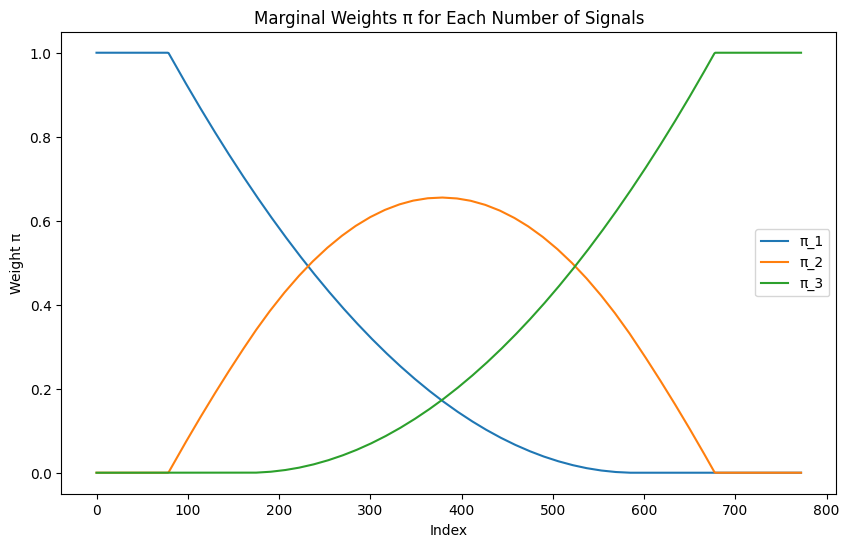

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.16633413499061195
        x: [-1.321e+00  1.105e-02 ... -7.279e-02  5.836e-03]
      nit: 738
      jac: [ 4.991e-07  6.521e-06 ... -1.418e-05 -2.179e-06]
     nfev: 773
     njev: 773
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


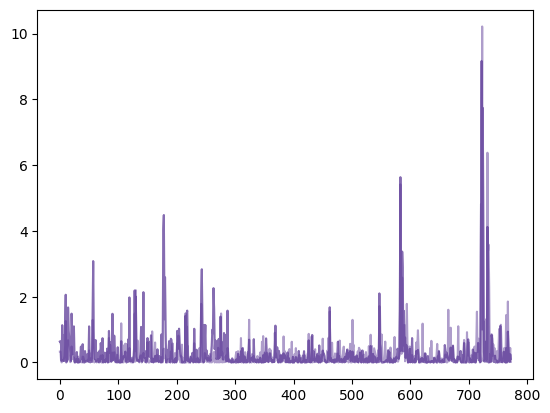

Regressing on signal  1
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.12249579598904588
        x: [-1.327e+00  1.842e-01 ...  4.599e-02  4.232e-02]
      nit: 475
      jac: [ 3.871e-06  4.489e-06 ...  3.628e-06 -4.977e-06]
     nfev: 494
     njev: 494
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


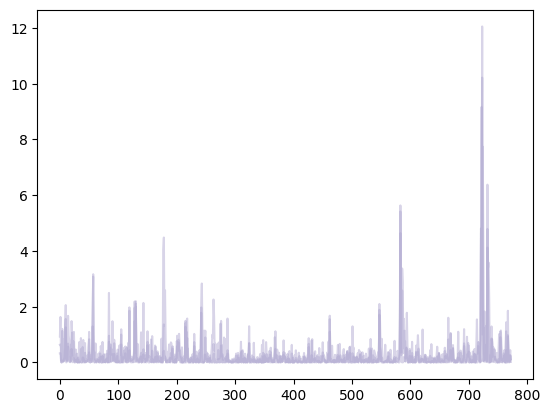

Regressing on signal  2
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.12868520515036802
        x: [-7.749e-01  4.980e-01 ...  4.501e-01  1.514e-01]
      nit: 1091
      jac: [-5.848e-06 -2.985e-07 ...  3.796e-06  5.105e-06]
     nfev: 1137
     njev: 1137
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


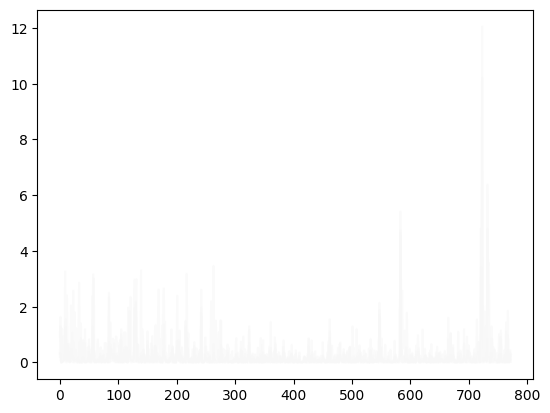

Optimizing gof erm...
Starting divide-and-conquer search for 2 change points...
WERM chpt estimate:  [264 392]
WERM gof:  103.90122030232082
Change point dates (ERM):  ['1982-01' '1992-09']
Done optimizing gof erm.


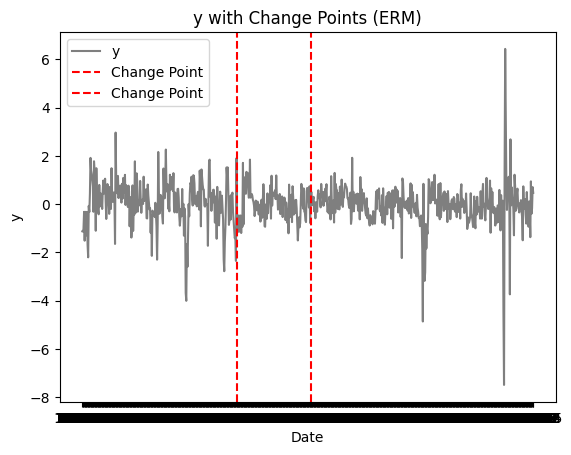

In [3]:
import WERM.config
import WERM.gof
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import matplotlib.pyplot as plt
import scipy
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

start_idx = 0
X = X_[start_idx:, :]
y = y_[start_idx:]
date = date_[start_idx:]
# Downsample the data by 2
# downsample_factor = 1
# X = X_[::downsample_factor, :]
# y = y_[::downsample_factor]
# date = date_[::downsample_factor]

n, p = X.shape
L = 3 # num signals. L-1 changepoints

# Least Squares Loss
# M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
def M(u, v, epsilon=1.345):
    residual = u - v
    abs_residual = jnp.abs(residual)
    condition = abs_residual <= epsilon
    squared_loss = 0.5 * jnp.square(residual)
    linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
    return jnp.where(condition, squared_loss, linear_loss)

# --- Preliminaries ---
# Set up the marginal prior
# Δ = lambda n: int(n/100)
# Lmin = L
# Lmax = L
# # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
# p_l = None
# num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
# assert η_arr.shape == (num_valid_configs, Lmax-1) and \
#     len(p_η_arr) == num_valid_configs
# assert ϕ.shape == (Lmax, n)

### --- Compute weights using analytical formula --- ###
# Weights computed according to {L-1 choose ℓ -1} * (i/n)^{ℓ-1} * (1 - i/n)^{L-ℓ}
# where ℓ is the number of signals, i is the index of the signal, and n is the total number of signals.
# π = lambda ℓ, i, n: (scipy.special.comb(L-1, ℓ-1) * (i/n)**(ℓ-1) * (1 - i/n)**(L-ℓ))
# ϕ = np.zeros((L, n)) # Lxn matrix
# for ℓ in range(1, L+1):
#     for i in range(1, n+1):
#         ϕ[ℓ-1, i-1] = π(ℓ, i, n)
# # Normalize ϕ so that it sums to 1 for each signal
# ϕ = ϕ / np.sum(ϕ, axis=1, keepdims=True) # Lxn matrix

Δ = lambda n: int(n/10)
Lmin = L
Lmax = L
# p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
p_l = None
n_small = 50
π = WERM.config.extrapolated_marginals(Lmin, Lmax, Δ(n_small), n_small = n_small, n_large = n, p_l = p_l)
# Plot the rows of π
plt.figure(figsize=(10, 6))
for ℓ in range(L):
    plt.plot(np.arange(n), π[ℓ, :], label=f'π_{ℓ+1}')
plt.title('Marginal Weights π for Each Number of Signals')
plt.xlabel('Index')
plt.ylabel('Weight π')
plt.legend()
plt.show()

# --- Run Weighted ERM and compare with the fixed point equations --- #
B̂ = np.zeros((p, L))

# Time the execution of the ERM and save it
start_time_erm = time.time()
for ℓ_ in range(L): 

    # Compute the empirical risk minimization (ERM) solution and metrics
    print("Regressing on signal ", ℓ_)
    sample_weight = π[ℓ_, :] / np.sum(π[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

    # Compute weighted ERM estimator
    empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
    res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
    print("ERM opt result: ", res) 
    β̂ = res.x
    B̂[:, ℓ_] = β̂

    ### --- Compute Change point estimates --- ###

    ## Compute Chgpt estimate for ERM
    PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99'] * 4
    for ℓ in range(L):
        plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ)) 
    plt.show()

print("Optimizing gof erm...")
# η̂, gof_list = WERM.gof.chgpt_gof(M, X @ B̂, y, η_arr, p_η_arr, γ = 1, gof_list_output = True)
# η̂, gof_list = WERM.gof.chgpt_gof_binary_seg(M, X @ B̂, y, η_arr, p_η_arr, γ = 1.0, combinations = True, gof_list_output = False, min_window_size = 30)
# η̂, opt_gof = WERM.gof.chgpt_gof_binary_seg_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=0.0, min_window_size=300, gof_opt_output=True)
# η̂ = WERM.gof.chgpt_gof_brute_force_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, batch_size=4096)
# η̂, opt_gof = WERM.gof.chgpt_gof_bf_mem_eff(M, X @ B̂, y, n, L, Δ(n), γ=1.0, L_is_upper_bound = False, batch_size=4096, gof_opt_output=True)
η̂, opt_gof = WERM.gof.chgpt_gof_divide_conquer(M, X @ B̂, y, n, L, Δ(n), γ=0.0, L_is_upper_bound = False, gof_opt_output=True)
# # Scatter the gof list
# plt.scatter(np.arange(len(gof_list)), gof_list, c='blue', alpha=0.5)
# plt.title('Goodness of Fit for Change Point Estimates (ERM)')
# plt.xlabel('Change Point Estimate (η)')
# plt.ylabel('Goodness of Fit')
# plt.grid()
# plt.show()
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
print("WERM gof: ", opt_gof)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

WERM chpt estimate:  [155 334 654]
Change point dates (ERM):  ['1972-12' '1987-11' '2014-07']
Done optimizing gof erm.


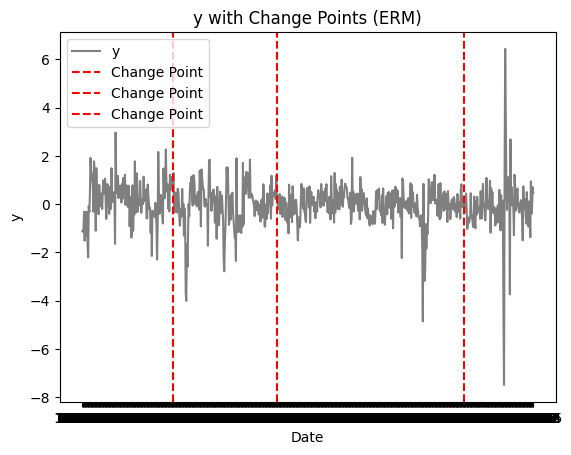

In [9]:
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

In [11]:
# Save results to logs
results = {
    'B̂': B̂,
    'η̂': η̂,
    'chgpt_dates_erm': chgpt_dates_erm
}
# Save the results to a file
with open('WERM_results_bf.pkl', 'wb') as f:
    pickle.dump(results, f)
# Print the results
print("Results saved to 'WERM_results.pkl'.")
# Load the results from the file

Results saved to 'WERM_results.pkl'.


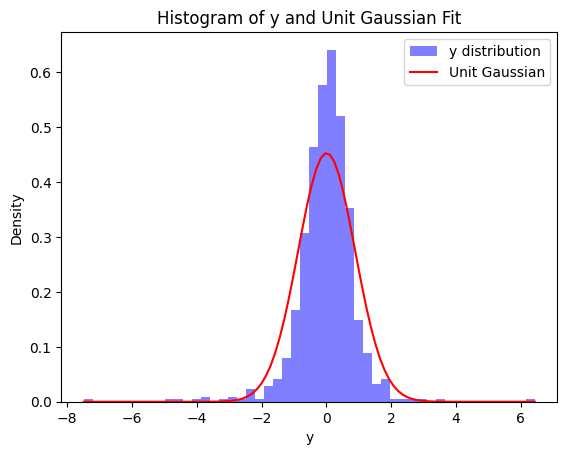

In [10]:
# Plot a histogram of y, and measure how close it is to a unit Gaussian
plt.hist(y, bins=50, density=True, alpha=0.5, color='blue', label='y distribution')
x = np.linspace(np.min(y), np.max(y), 100)
plt.plot(x, scipy.stats.norm.pdf(x, np.mean(y), np.std(y)), color='red', label='Unit Gaussian')
plt.title('Histogram of y and Unit Gaussian Fit')
plt.xlabel('y')
plt.ylabel('Density')
plt.legend()
plt.show()

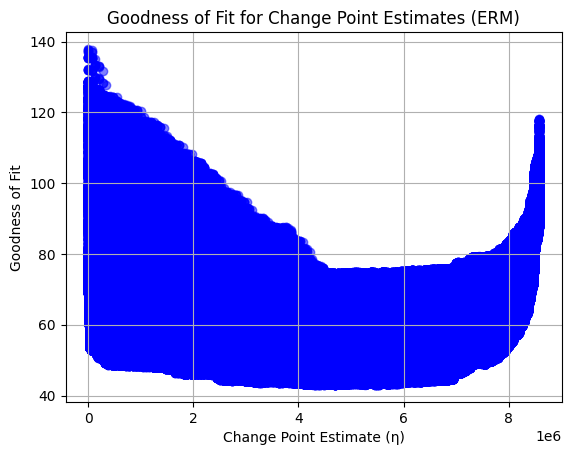

WERM chpt estimate:  [ 90 162 272]
Change point dates (ERM):  ['1975-01' '1987-01' '2005-05']
Done optimizing gof erm.


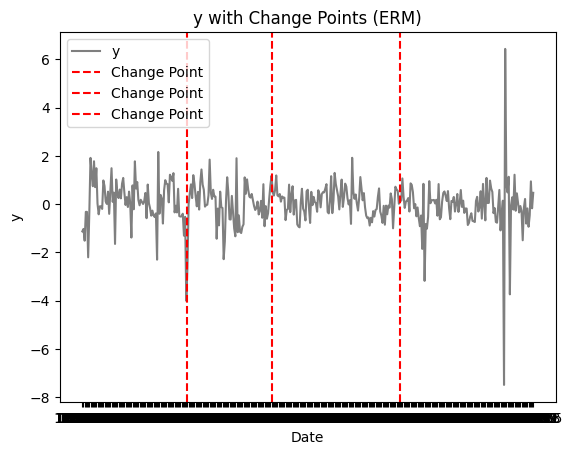

In [5]:
# Scatter the gof list
plt.scatter(np.arange(len(gof_list)), gof_list, c='blue', alpha=0.5)
plt.title('Goodness of Fit for Change Point Estimates (ERM)')
plt.xlabel('Change Point Estimate (η)')
plt.ylabel('Goodness of Fit')
plt.grid()
plt.show()
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

# Inspect Regression Vectors

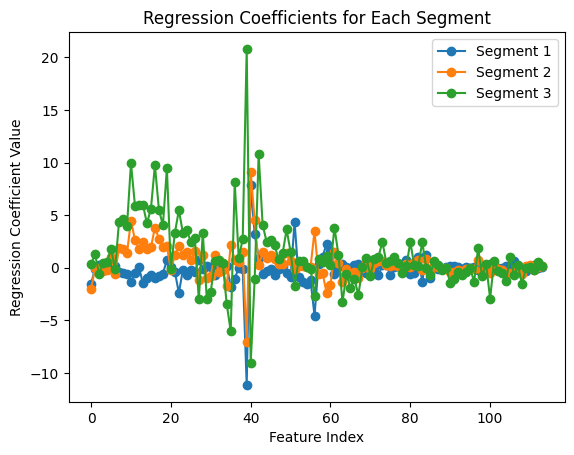

In [4]:
# Segment the data based on the estimated change points, and compute the regression vector for each segment
segments = []
# Ensure η̂ includes the start and end of the data points
# Example: η̂ = [0, 50, 100, 150] for data with 150 points and 3 segments
η̂_extended = np.concatenate(([0], η̂, [len(y)]))  # Add start and end indices
for i in range(0, len(η̂_extended)-1):
    start = η̂_extended[i]
    end = η̂_extended[i + 1]
    segment_X = X[start:end, :]
    segment_y = y[start:end]
    segments.append((segment_X, segment_y))

# Compute the regression vector for each segment
# p should be the number of features, i.e., X.shape[1]
# L should be the number of segments, i.e., len(segments)
p = X.shape[1]
B̂_segments = np.zeros((p, len(segments)))

# Use enumerate to get both the index (i) and the data (segment)
for i, (segment_X, segment_y) in enumerate(segments):
    sample_weight = np.ones(segment_X.shape[0]) / segment_X.shape[0]  # Uniform weights
    empirical_risk = lambda β: jnp.multiply(M(segment_X @ β, segment_y), sample_weight).sum()
    
    # Ensure the initial guess has the correct shape (p,)
    initial_guess = np.zeros(p)
    
    res = scipy.optimize.minimize(empirical_risk, initial_guess, jac=jax.grad(empirical_risk), method='L-BFGS-B')
    
    # Use the index 'i' from enumerate for correct assignment
    B̂_segments[:, i] = res.x

# Plot the regression vector values for each segment
num_segments = B̂_segments.shape[1]
for ℓ in range(num_segments):
    # Corrected the label to use the segment index ℓ
    plt.plot(np.arange(p), B̂_segments[:, ℓ], label=f'Segment {ℓ+1}', marker='o')

plt.xlabel('Feature Index')
plt.ylabel('Regression Coefficient Value')
plt.title('Regression Coefficients for Each Segment')
plt.legend()
plt.show()

In [7]:
y.shape

(387,)

In [8]:
X.shape

(387, 114)

In [10]:
segment_X.shape

(110, 114)

In [13]:
segment_y.shape

(110,)

In [12]:
segments.index((segment_X, segment_y))

ValueError: operands could not be broadcast together with shapes (72,114) (110,114) 

In [15]:
(segment_X, segment_y)

(array([[ 0.07613151,  0.31765296, -0.39830689, ..., -1.38215049,
         -0.13204158, -0.55852267],
        [-0.12682225, -0.1705261 , -0.12639859, ...,  1.58335979,
         -0.00505133,  0.18542606],
        [-0.30342986, -0.202061  , -0.04362784, ...,  0.57732183,
          0.40331853,  0.03957114],
        ...,
        [-0.05288516, -0.20862615, -0.08682139, ..., -0.33340029,
          0.89830965, -0.04451295],
        [-0.08741294, -0.0126345 , -0.1703772 , ..., -0.01724417,
          0.12660457,  2.15547875],
        [-0.06644793, -0.07637444, -0.17031469, ..., -0.24136788,
         -0.53907449, -0.73789514]], shape=(110, 114)),
 array([ 1.17651692,  0.47776234,  0.35501374,  0.57622038,  1.18855661,
         0.36893136,  0.32175588,  0.41943903,  0.10210696,  0.3193322 ,
         0.25798976,  0.27143652, -0.6620578 , -0.23613416, -0.20180511,
         0.80809872, -0.33139021,  0.39050117,  0.74041784, -0.43337958,
         0.15328938,  0.17632335, -0.84037456, -0.92440183, -0.